# 01 · Exploring the data (EDA)

**Goal:** understand the traffic data *before* building anything, and find every problem we'll have to fix.

EDA isn't a gallery of plots. It's a list of questions. Each one gets the same four steps:

1. **The question**: what we want to know
2. **The code**
3. **How to read the output**
4. **So what?**: the decision it leads to

> Tip: run the cells in order, top to bottom (*Run All*). Running them out of order is a common source of confusing results.

In [1]:
# --- setup: run this cell first ---
import sys
sys.path.insert(0, "../src")          # so we can use the project's own helpers

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import path                # path("raw", "file.csv") -> full path to data/raw/file.csv

plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.width", 120)

## Step 1 · Load the raw data and look at it

We start with the **raw** file, exactly as the client delivered it, because that's where the problems are.

In [2]:
raw = pd.read_csv(path("raw", "traffic_sensor_log.csv"))
weather = pd.read_csv(path("raw", "weather_observations.csv"))

print("rows, columns:", raw.shape)
raw.head(3)

rows, columns: (178468, 17)


,road_id,road_name,latitude,longitude,weather_station_id,date,time,traffic_volume,vehicle_count,vehicle_type_dist,avg_speed,occupancy,congestion_level,travel_time,accident_count,signal_timing,road_capacity
0,NL-007,Kingsway @ Park,28.647903,77.149142,WS-NORTH,2025-02-26,07:30,706.0,706,"{""2W"": 0.37, ""Car"": 0.43, ""LCV"": 0.11, ""HCV"": ...",31.2,59.6,Moderate,2.12,0,54,1928
1,NL-014,Industrial Link B,28.594749,77.253501,WS-CENTRAL,2025-03-23,21:00,308.0,308,"{""2W"": 0.43, ""Car"": 0.39, ""LCV"": 0.08, ""HCV"": ...",53.5,16.8,Free-flow,2.03,0,32,2327
2,NL-022,Old Town @ Clock,28.674521,77.219835,WS-NORTH,2025-04-05,11:00,342.0,342,"{""2W"": 0.4, ""Car"": 0.33, ""LCV"": 0.15, ""HCV"": 0...",49.9,27.5,Free-flow,3.46,0,38,1771


**How to read it:** one row = **one road segment in one 30-minute window**. `traffic_volume` is the number of vehicles that passed in those 30 minutes.

**So what?** Every target we want to predict is a column here: `traffic_volume` and `avg_speed` (numbers, so **regression**), `congestion_level` (a label, so **classification**).

## Q1 · Are there impossible values?

`describe()` gives the average, minimum and maximum of every number column. **Always read the min and max**, not just the average: impossible values hide there.

In [3]:
raw[["traffic_volume", "avg_speed", "occupancy", "travel_time"]].describe().loc[["mean", "min", "max"]].round(1)

,traffic_volume,avg_speed,occupancy,travel_time
mean,430.6,42.4,31.4,3.6
min,-59.0,6.7,3.0,0.8
max,2090.0,319.6,259.9,29.9


**How to read it:**
- `traffic_volume` min is **negative**. You can't count fewer than zero cars.
- `avg_speed` max is about **320 km/h**, on city roads.
- `occupancy` (how much of the time a car is over the sensor, 0 to 100%) goes above **100%**.

Now count them with a **boolean mask**: a column of True/False, one per row. `.sum()` counts the Trues.

In [4]:
print("negative volume:      ", (raw["traffic_volume"] < 0).sum())
print("speed over 200 km/h:  ", (raw["avg_speed"] > 200).sum())
print("occupancy over 100%:  ", (raw["occupancy"] > 100).sum())

negative volume:       241
speed over 200 km/h:   237
occupancy over 100%:   234


**So what?** Hundreds of broken sensor readings. They must be fixed before training, or the model learns that negative traffic is possible.

## Q2 · What's missing?

`isna().sum()` counts empty cells per column.

In [5]:
missing = raw.isna().sum()
missing[missing > 0]

traffic_volume       4387
avg_speed            4382
occupancy            4383
congestion_level    26883
dtype: int64

**Watch out for this trap:** `value_counts()` hides missing values by default.

In [6]:
print(raw["congestion_level"].value_counts())               # blanks are silently left out
print()
print(raw["congestion_level"].value_counts(dropna=False))   # now we see them (NaN)

congestion_level
Free-flow    93029
Moderate     36191
Heavy        14008
Severe        8357
Name: count, dtype: int64

congestion_level
Free-flow    93029
Moderate     36191
NaN          26883
Heavy        14008
Severe        8357
Name: count, dtype: int64


**So what?** About 15% of congestion labels are blank. The data dictionary gives a formula to fill them (vehicles ÷ half-hour capacity), so we **derive** them in cleaning instead of dropping those rows.

## Q3 · Are there duplicate rows?

In [7]:
print("exact duplicate rows:", raw.duplicated().sum())

exact duplicate rows:

 1767


**So what?** A sensor that logged the same reading twice would count double in training. Duplicates get dropped first.

## Q4 · Does any column already know the right answer?

This is the most useful question in the whole notebook. If two columns always agree, one can repair the other.

In [8]:
good = raw[raw["traffic_volume"] >= 0]
print("traffic_volume == vehicle_count on good rows:", (good["traffic_volume"] == good["vehicle_count"]).mean())

raw[raw["traffic_volume"] < 0][["road_id", "time", "traffic_volume", "vehicle_count"]].head(3)

traffic_volume == vehicle_count on good rows: 1.0


,road_id,time,traffic_volume,vehicle_count
676,NL-009,21:30,-6.0,247
1065,NL-014,23:30,-33.0,119
1397,NL-007,20:30,-38.0,258


**How to read it:** on every good row the two columns are **identical** (1.0 = 100%). Where `traffic_volume` is broken (like −6), `vehicle_count` still holds the real number (247).

**So what?** We don't have to *guess* broken volumes, we can copy them back exactly. **Always look for a backup column before you fill in missing values.** (Speed works the same way: `travel_time = 60 × road length ÷ speed`, so a broken speed can be recomputed from travel time.)

## Q5 · Are the categories spelled consistently?

In [9]:
weather["weather_condition"].value_counts()

weather_condition
Clear       5647
Cloudy      1504
clear       1284
CLEAR       1237
Overcast     358
cloudy       340
Rain         307
Fog           59
rain          48
rainy         37
RAIN          34
foggy         10
FOG            7
Name: count, dtype: int64

**How to read it:** "Clear", "clear" and "CLEAR" are the same weather, and so are "Rain", "rain " (trailing space!), "RAIN" and "rainy". That's **13 spellings for 5 conditions**.

**So what?** To a model, each spelling is a different category. Clean them with `.str.strip().str.lower()` plus a mapping.

## Q6 · What does a normal day look like?

From here on we use the **cleaned** table (made by `run_pipeline.py`), so broken values don't distort the picture. `is_imputed == 0` keeps only real sensor readings, not rebuilt gaps.

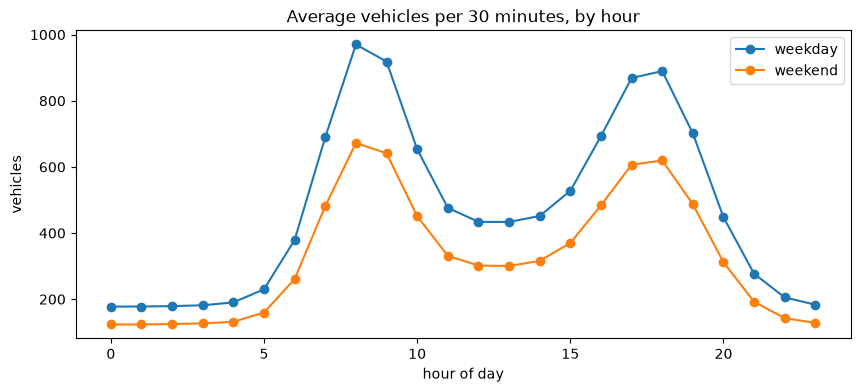

morning peak: 8 h -> 970 vehicles
evening peak: 18 h -> 890 vehicles


In [10]:
df = pd.read_parquet(path("processed", "flowcast_features_v1.0.parquet"))
real = df[df["is_imputed"] == 0]

hour = real["timestamp"].dt.hour
day_type = np.where(real["is_weekend"] == 1, "weekend", "weekday")
profile = real.groupby([hour, day_type])["traffic_volume"].mean().unstack()

profile.plot(marker="o", title="Average vehicles per 30 minutes, by hour")
plt.xlabel("hour of day"); plt.ylabel("vehicles")
plt.show()
wk = profile["weekday"]
print("morning peak:", wk.loc[:11].idxmax(), "h ->", round(wk.loc[:11].max()), "vehicles")
print("evening peak:", wk.loc[12:].idxmax(), "h ->", round(wk.loc[12:].max()), "vehicles")

**How to read it:** two rush hours on weekdays (around 8 am and 6 pm), and a flatter, later weekend.

**So what?** Time of day and weekday/weekend carry a lot of the signal, so they become features. It also tells us errors will be biggest at rush hour, because that's where the numbers are biggest.

## Q7 · How balanced are the labels we'll predict?

In [11]:
print((real["congestion_level"].value_counts(normalize=True) * 100).round(1))
print()
print("windows with an accident: %.2f%%" % ((real["accident_count"] > 0).mean() * 100))

congestion_level
Free-flow    61.4
Moderate     23.8
Heavy         9.2
Severe        5.5
Name: proportion, dtype: float64

windows with an accident: 0.93%


**How to read it:** most windows are Free-flow, Severe is rare, and accidents happen in under 1% of windows.

**So what?** **Accuracy would lie to us.** A model that always says "no accident" is 99% accurate and completely useless. So we'll judge congestion with **macro-F1** and accidents with **ROC-AUC** (explained in notebook 03).

## Q8 · Which inputs move together with traffic volume?

A **correlation** is a number from −1 to +1: +1 means two columns rise together, −1 means one rises as the other falls, 0 means no straight-line link.

In [12]:
cols = ["traffic_volume_lag1", "traffic_volume_lag48", "avg_speed_lag1", "is_peak_period", "is_rain_lag1"]
real[cols + ["traffic_volume"]].corr()["traffic_volume"].drop("traffic_volume").round(3)

traffic_volume_lag1     0.935
traffic_volume_lag48    0.867
avg_speed_lag1         -0.825
is_peak_period          0.712
is_rain_lag1           -0.038
Name: traffic_volume, dtype: float64

**How to read it:**
- `traffic_volume_lag1` (volume 30 minutes ago): +0.93, the strongest clue.
- `avg_speed_lag1`: negative, because more cars means slower traffic.
- `is_rain_lag1`: almost 0. Rain barely matters overall.

**So what?** The recent past is the best predictor, which is why the model gets "lag" features.

## Q9 · The trap: does fog really reduce traffic?

A good EDA habit: when two groups differ, check whether something *else* explains it.

In [13]:
peak = real[real["is_peak_period"] == 1]
peak.groupby("weather_condition")[["traffic_volume", "avg_speed"]].mean().round(1)

,traffic_volume,avg_speed
weather_condition,,
Clear,836.2,24.6
Cloudy,811.6,25.9
Fog,475.0,36.2
Overcast,822.7,25.3
Rain,676.5,28.4


Fog looks like it cuts traffic by almost half, *and* makes cars faster. Suspicious. When does fog happen?

In [14]:
print(real[real["weather_condition"] == "Fog"]["timestamp"].dt.hour.value_counts().sort_index())

timestamp
4    302
5    460
6    356
7    130
Name: count, dtype: int64


**How to read it:** fog only ever happens between **4 and 7 am**, before the morning rush. So "fog = less traffic" is really "**early morning** = less traffic".

This is called **confounding**: a third thing (time of day) drives both. **Compare like with like** (same hour) before believing a difference between groups.

## What we learned, and what happens next

| Finding | Action in cleaning (`src/clean.py`) |
|---|---|
| Negative volumes, impossible speeds | Recover exactly from `vehicle_count` and `travel_time` |
| Occupancy over 100% | Cap at 100 |
| Blank congestion labels | Derive from the V/C formula |
| 1,767 duplicate rows | Drop |
| 13 weather spellings | Map to 5 |
| Rush-hour pattern, strong lag correlation | Time and lag features (`src/features.py`) |
| Rare Severe and rare accidents | Use macro-F1 and ROC-AUC, not accuracy |

Next: **02_cleaning.ipynb**.